# AlphaEarth Model Predictions Visualization

This notebook loads a trained model and visualizes its predictions on a new sample.

In [1]:
import sys
import json
from pathlib import Path
import random

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Add paths
project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(Path.cwd().parent / 'scripts'))

# Import utilities
from utilities import KernelNN_subgraph, setup_device, get_output_affinities
from utilities_alphaearth import (
    prepare_dataframe,
    create_subgraph_sample,
    create_regular_grid_from_data,
    get_global_bounds,
    load_geotiff_subregion,
    year_from_filename
)

print(f'Project root: {project_root}')

Project root: /Volumes/T7-storage/NOFE


## 1. Configuration

Specify the model ID to load.

In [2]:
# Set model ID (with timestamp)
model_id = 'model1_subgraph-subgraph-2026-01-15_t14-30-29'  # Update this to your trained model

# Paths
trained_models_path = project_root / 'alphaEarth' / 'trained_models'
training_logs_path = project_root / 'alphaEarth' / 'training_logs'
data_path = project_root.parent / 'alphaEarth' / 'data'  # Adjust if needed

# Device setup
device = setup_device()
print(f'Using device: {device}')

Using device: mps


## 2. Load Model and Configuration

In [3]:
# Load full configuration (includes model, dataset, and training configs)
config_path = training_logs_path / 'configs' / f'{model_id}.json'
with open(config_path, 'r') as f:
    config = json.load(f)

# Load loss records
loss_df = pd.read_csv(training_logs_path / 'loss_records' / f'{model_id}.csv')

print('Configuration:')
for key, value in config.items():
    print(f'  {key}: {value}')

print(f'\Training completed {len(loss_df)} epochs')
print(f'Final training loss: {loss_df["loss"].iloc[-1]:.4f}')
print(f'Final validation loss: {loss_df["val_loss"].iloc[-1]:.4f}')

Configuration:
  dataset_id: subgraph_config
  model_id: model1_subgraph
  epochs: 20
  batch_size: 1
  learning_rate: 1e-05
  scheduler_step: 4
  scheduler_gamma: 0.8
  random_seed: 42
  width: 32
  ker_width: 32
  depth: 4
  input_node_features: 64
  output_node_features: 5
  edge_attr: 73
  out_width: 3
  k_in: 5
  k_out: 5
  k_cross: 3
  perplexity: 15
  n_points_input_min: 1000
  n_points_input_max: 2000
  n_points_lat_out: 100
  n_points_lon_out: 100
  train_samples_per_year: 100
  test_samples_per_year: 100
  lat_min: 59.66
  lat_max: 59.73
  lon_min: 10.79
  lon_max: 10.86
  train_years: [2018, 2019, 2020]
  test_years: [2021]
  cache_region_data: True
\Training completed 16 epochs
Final training loss: 740.1438
Final validation loss: 908.4447


In [4]:
config

{'dataset_id': 'subgraph_config',
 'model_id': 'model1_subgraph',
 'epochs': 20,
 'batch_size': 1,
 'learning_rate': 1e-05,
 'scheduler_step': 4,
 'scheduler_gamma': 0.8,
 'random_seed': 42,
 'width': 32,
 'ker_width': 32,
 'depth': 4,
 'input_node_features': 64,
 'output_node_features': 5,
 'edge_attr': 73,
 'out_width': 3,
 'k_in': 5,
 'k_out': 5,
 'k_cross': 3,
 'perplexity': 15,
 'n_points_input_min': 1000,
 'n_points_input_max': 2000,
 'n_points_lat_out': 100,
 'n_points_lon_out': 100,
 'train_samples_per_year': 100,
 'test_samples_per_year': 100,
 'lat_min': 59.66,
 'lat_max': 59.73,
 'lon_min': 10.79,
 'lon_max': 10.86,
 'train_years': [2018, 2019, 2020],
 'test_years': [2021],
 'cache_region_data': True}

In [5]:
# Initialize model with configuration
model = KernelNN_subgraph(
    width=config['width'],
    ker_width=config['ker_width'],
    depth=config['depth'],
    ker_in=config['edge_attr'],
    known_node_dim=config['input_node_features'],
    unknown_node_dim=config['output_node_features'],
    out_width=config['out_width'],
).to(device)

# Load trained weights
model_path = trained_models_path / f'{model_id}.pth'
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

print(f'Model loaded: {model_id}')
print(f'Total parameters: {sum(p.numel() for p in model.parameters()):,}')

Model loaded: model1_subgraph-subgraph-2026-01-15_t14-30-29
Total parameters: 76,835


## 3. Create New Sample

Use the same functionality as dataset creation to generate a single sample.

In [6]:
# Choose a year and file (use test year for out-of-sample prediction)
test_year = 2019  # First test year
tif_path = data_path / f'sat_emb_{test_year}.tif'

n_points_input = 5

n_points_output_grid_latitude = 3
n_points_output_grid_longitude = 3

if not tif_path.exists():
    print(f'Warning: File not found: {tif_path}')
    print('Available files:')
    for f in sorted(data_path.glob('sat_emb_*.tif')):
        print(f'  {f.name}')
else:
    print(f'Using data file: {tif_path.name}')
    
    # Define bounding box (use config bounds)
    bbox = (
        config['lon_min'],
        config['lat_min'],
        config['lon_max'],
        config['lat_max']
    )
    
    print(f'Bounding box: lat [{bbox[1]}, {bbox[3]}], lon [{bbox[0]}, {bbox[2]}]')
    
    # Load and prepare data
    print('Loading region data...')
    df = prepare_dataframe(str(tif_path), bbox)
    print(f'Loaded {len(df)} grid points')
    
    # Create output grid from the data
    print('Creating output grid...')
    grid_indices, grid_df_temp = create_regular_grid_from_data(
        df, 
        n_points_output_grid_latitude, 
        n_points_output_grid_longitude
    )
    grid_df = df.iloc[grid_indices].reset_index(drop=True)
    print(f'Created grid with {len(grid_df)} points')
    
    # Create graph sample using same parameters as training
    print('Creating graph sample...')
    sample, _ = create_subgraph_sample(
        df_full=df,
        year=test_year,
        n_points_input_min=n_points_input,
        n_points_input_max=n_points_input,
        grid_df=grid_df,
        k_in=config['k_in'],
        k_out=config['k_out'],
        k_cross=config['k_cross'],
        perplexity=config['perplexity'],
        device=device,
        filename=tif_path.name,
        cached_output=None
    )
    
    print(f'Sample created:')
    print(f'  Input nodes: {sample.vert_in.shape[0]}')
    print(f'  Output nodes: {sample.vert_out.shape[0]}')
    print(f'  Input edges: {sample.edge_idx_in.shape[1]}')
    print(f'  Output edges: {sample.edge_idx_out.shape[1]}')
    print(f'  Cross edges: {sample.cross_edge_idx.shape[1]}')
    print(f'  Input features: {sample.vert_in_features.shape[1]}')
    print(f'  Year: {sample.year}')

Using data file: sat_emb_2019.tif
Bounding box: lat [59.66, 59.73], lon [10.79, 10.86]
Loading region data...
Loaded 30000 grid points
Creating output grid...
Created grid with 9 points
Creating graph sample...
Sample created:
  Input nodes: 5
  Output nodes: 9
  Input edges: 20
  Output edges: 45
  Cross edges: 27
  Input features: 64
  Year: 2019


## 4. Make Prediction

Run the sample through the trained model.

In [7]:
# Move sample to device
sample = sample.to(device)

# Make prediction
with torch.no_grad():
    output = model(sample)
    # For subgraph, we use the output subgraph edges
    predicted_affinities = get_output_affinities(output, sample.edge_idx_out)

print(f'Prediction shape: {output.shape}')
print(f'Output affinities shape: {predicted_affinities.shape}')
print(f'Input affinities shape: {sample.input_affinities.shape}')

Prediction shape: torch.Size([9, 3])
Output affinities shape: torch.Size([9, 5])
Input affinities shape: torch.Size([9, 5])


## 5. Visualize Results

Compare input and predicted affinities.

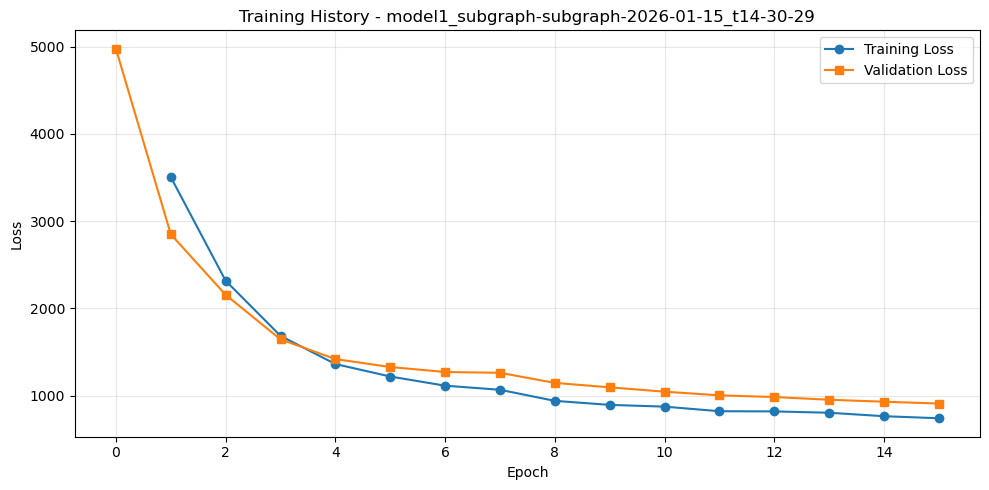

In [8]:
# Plot training history
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(loss_df['epoch'], loss_df['loss'], label='Training Loss', marker='o')
ax.plot(loss_df['epoch'], loss_df['val_loss'], label='Validation Loss', marker='s')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title(f'Training History - {model_id}')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

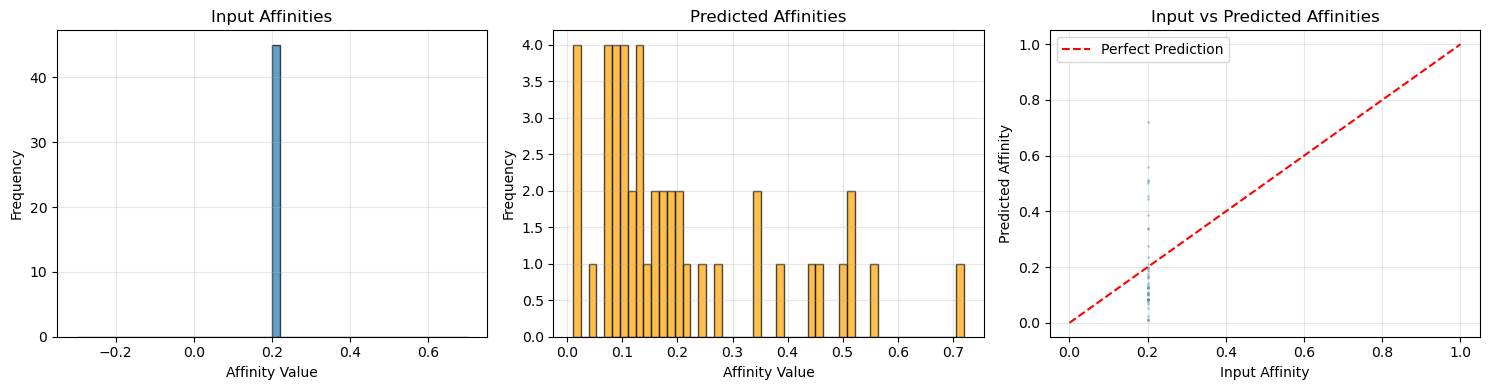

Correlation between input and predicted affinities: nan


/Users/laueb4818/miniforge3/envs/neural-operators/lib/python3.9/site-packages/numpy/lib/function_base.py:2853: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/laueb4818/miniforge3/envs/neural-operators/lib/python3.9/site-packages/numpy/lib/function_base.py:2854: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [10]:
# Compare input vs predicted affinities
input_aff = sample.input_affinities.cpu().numpy().flatten()
pred_aff = predicted_affinities.cpu().numpy().flatten()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Input affinities histogram
axes[0].hist(input_aff, bins=50, alpha=0.7, edgecolor='black')
axes[0].set_title('Input Affinities')
axes[0].set_xlabel('Affinity Value')
axes[0].set_ylabel('Frequency')
axes[0].grid(True, alpha=0.3)

# Predicted affinities histogram
axes[1].hist(pred_aff, bins=50, alpha=0.7, color='orange', edgecolor='black')
axes[1].set_title('Predicted Affinities')
axes[1].set_xlabel('Affinity Value')
axes[1].set_ylabel('Frequency')
axes[1].grid(True, alpha=0.3)

# Scatter plot: input vs predicted
axes[2].scatter(input_aff, pred_aff, alpha=0.3, s=1)
axes[2].plot([0, 1], [0, 1], 'r--', label='Perfect Prediction')
axes[2].set_title('Input vs Predicted Affinities')
axes[2].set_xlabel('Input Affinity')
axes[2].set_ylabel('Predicted Affinity')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Compute correlation
correlation = np.corrcoef(input_aff, pred_aff)[0, 1]
print(f'Correlation between input and predicted affinities: {correlation:.4f}')

{'whiskers': [<matplotlib.lines.Line2D at 0x32c6bd0d0>,
 'caps': [<matplotlib.lines.Line2D at 0x32c6bd610>,
 'boxes': [<matplotlib.lines.Line2D at 0x32c6a9df0>],
 'medians': [<matplotlib.lines.Line2D at 0x32c6bdac0>],
 'fliers': [<matplotlib.lines.Line2D at 0x32c6bdd60>],
 'means': []}

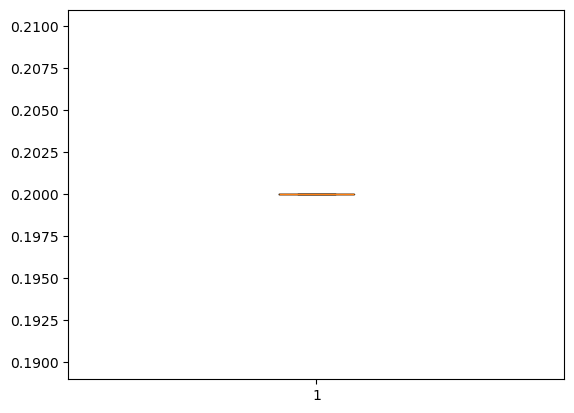

In [12]:
plt.boxplot(input_aff)

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Node locations
locations = sample.locations

fig, ax = plt.subplots(figsize=(10, 8))

# --- Plot edges FIRST (so they stay behind nodes) ---
edge_index = sample.edge_index.cpu().numpy()
num_edges = edge_index.shape[1]

for i in range(num_edges):
    src, dst = edge_index[:, i]
    ax.plot(
        [locations['lon'].iloc[src], locations['lon'].iloc[dst]],
        [locations['lat'].iloc[src], locations['lat'].iloc[dst]],
        color='black',
        alpha=0.1,      # low alpha to avoid clutter
        linewidth=0.5,
        zorder=1
    )

# --- Plot nodes ---
ax.scatter(
    locations['lon'],
    locations['lat'],
    color='tab:blue',
    s=50,
    alpha=0.7,
    edgecolors='black',
    linewidth=0.5,
    zorder=2
)

# --- Labels & styling ---
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(
    f'Graph Structure: {sample.x.shape[0]} nodes, {num_edges} edges'
)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


AttributeError: 'GlobalStorage' object has no attribute 'locations'

# Napari RGB Visualization of Model Predictions

Visualize the 3 output dimensions of the model's predictions as RGB channels.

In [50]:
A = np.array(output.cpu().numpy())
B = np.array(sample.vert_out_gps.cpu().numpy())

In [ ]:
# Per point plot

# --- Normalize colors ---
A = A.astype(float)

norms = np.linalg.norm(A, axis=1, keepdims=True)
norms[norms == 0] = 1.0
A_norm = A / norms

# Optional brightness scaling
V = 0.6
colors = np.clip(A_norm * V, 0, 1)

# --- Coordinates ---
points = np.column_stack([B[:, 0], B[:, 1]])  # (lat, lon)

# --- Napari viewer ---
viewer = napari.Viewer()

viewer.add_points(
    points,
    face_color=colors,
    size=5,
    blending='additive',
    name='nodes'
)

napari.run()

In [ ]:
# Plot as interpolated images

import numpy as np
import napari
from scipy.interpolate import griddata

# -----------------------------
# Input data
# A: (N, 3)  -> non-normalized RGB channels
# B: (N, 2)  -> (latitude, longitude)
# -----------------------------

A = A.astype(float)
lat = B[:, 0]
lon = B[:, 1]

# -----------------------------
# Per-channel normalization
# -----------------------------

A_norm = np.zeros_like(A)

for c in range(3):
    channel = A[:, c]
    cmin = channel.min()
    cmax = channel.max()
    if cmax > cmin:
        A_norm[:, c] = (channel - cmin) / (cmax - cmin)
    else:
        A_norm[:, c] = 0.0

# Optional global brightness scaling (prevents additive washout)
V = 0.5
A_norm = np.clip(A_norm * V, 0, 1)

# -----------------------------
# Create regular lat–lon grid
# -----------------------------

grid_size = 300  # adjust resolution here

lat_grid = np.linspace(lat.min(), lat.max(), grid_size)
lon_grid = np.linspace(lon.min(), lon.max(), grid_size)

lon_mesh, lat_mesh = np.meshgrid(lon_grid, lat_grid)

points = np.column_stack([lon, lat])

# -----------------------------
# Interpolate each channel
# -----------------------------

R = griddata(points, A_norm[:, 0], (lon_mesh, lat_mesh), method='linear')
G = griddata(points, A_norm[:, 1], (lon_mesh, lat_mesh), method='linear')
B = griddata(points, A_norm[:, 2], (lon_mesh, lat_mesh), method='linear')

R[np.isnan(R)] = 0.0
G[np.isnan(G)] = 0.0
B[np.isnan(B)] = 0.0

# -----------------------------
# Stack into RGB image
# -----------------------------

rgb_image = np.stack([R, G, B], axis=-1)  # (H, W, 3)

# -----------------------------
# Napari visualization
# -----------------------------

viewer = napari.Viewer()

viewer.add_image(
    rgb_image,
    name="Interpolated RGB",
    rgb=True,
    interpolation2d="linear"
)

napari.run()


/var/folders/sw/tjsbk4pj7q9gs_91lbj2_2rc0000gp/T/ipykernel_85658/424639933.py:73: FutureWarning: Argument 'interpolation' is deprecated, please use 'interpolation2d' instead. The argument 'interpolation' was deprecated in 0.4.17 and it will be removed in 0.6.0.
  viewer.add_image(


In [64]:
import numpy as np
import napari
from scipy.interpolate import griddata

# -----------------------------
# Input data
# A: (N, 3)  -> non-normalized RGB channels
# B: (N, 2)  -> (latitude, longitude)
# -----------------------------

A = A.astype(float)
lat = B[:, 0]
lon = B[:, 1]
"""
# -----------------------------
# Per-channel normalization
# -----------------------------

A_norm = np.zeros_like(A)

for c in range(3):
    channel = A[:, c]
    cmin = channel.min()
    cmax = channel.max()
    if cmax > cmin:
        A_norm[:, c] = (channel - cmin) / (cmax - cmin)
    else:
        A_norm[:, c] = 0.0

# Optional global brightness scaling (prevents additive washout)
V = 0.5
A_norm = np.clip(A_norm * V, 0, 1)
"""
# -----------------------------
# Per-channel percentile normalization
# -----------------------------

A_norm = np.zeros_like(A)

p_low = 5.    # lower percentile
p_high = 95   # upper percentile

for c in range(3):
    channel = A[:, c]

    lo = np.percentile(channel, p_low)
    hi = np.percentile(channel, p_high)

    if hi > lo:
        channel_clipped = np.clip(channel, lo, hi)
        A_norm[:, c] = (channel_clipped - lo) / (hi - lo)
    else:
        A_norm[:, c] = 0.0

# -----------------------------
# Create regular lat–lon grid
# -----------------------------

grid_size = 300  # adjust resolution here

lat_grid = np.linspace(lat.min(), lat.max(), grid_size)
lon_grid = np.linspace(lon.min(), lon.max(), grid_size)

lon_mesh, lat_mesh = np.meshgrid(lon_grid, lat_grid)

points = np.column_stack([lon, lat])

# -----------------------------
# Interpolate each channel
# -----------------------------

Red = griddata(points, A_norm[:, 0], (lon_mesh, lat_mesh), method='linear')
Green = griddata(points, A_norm[:, 1], (lon_mesh, lat_mesh), method='linear')
Blue = griddata(points, A_norm[:, 2], (lon_mesh, lat_mesh), method='linear')

Red[np.isnan(Red)] = 0.0
Green[np.isnan(Green)] = 0.0
Blue[np.isnan(Blue)] = 0.0

# -----------------------------
# Stack into 3 separate layers
# -----------------------------

image_stack = np.stack([Red, Green, Blue], axis=0)  # shape: (3, H, W)
colormap_names = ['red', 'green', 'blue']
opacity_per_layer = 0.75  # reasonable for additive blending

# -----------------------------
# Napari visualization
# -----------------------------

viewer = napari.Viewer()

for i in range(3):
    viewer.add_image(
        image_stack[i],
        name=f'channel_{colormap_names[i]}',
        colormap=colormap_names[i],
        blending='additive',
        opacity=opacity_per_layer,
        interpolation2d='cubic'
    )

napari.run()


In [52]:
min(sample.vert_in_gps[:,0]), max(sample.vert_in_gps[:,0]), min(sample.vert_in_gps[:,1]), max(sample.vert_in_gps[:,1]),

(tensor(59.6601, device='mps:0'),
 tensor(59.7300, device='mps:0'),
 tensor(10.7900, device='mps:0'),
 tensor(10.8599, device='mps:0'))

In [53]:
min(sample.vert_out_gps[:,0]), max(sample.vert_out_gps[:,0]), min(sample.vert_out_gps[:,1]), max(sample.vert_out_gps[:,1]),

(tensor(59.6601, device='mps:0'),
 tensor(59.7300, device='mps:0'),
 tensor(10.7900, device='mps:0'),
 tensor(10.8599, device='mps:0'))

{'whiskers': [<matplotlib.lines.Line2D at 0x35fb4e160>,
 'caps': [<matplotlib.lines.Line2D at 0x35fb4e6a0>,
 'boxes': [<matplotlib.lines.Line2D at 0x35fb3ee80>,
 'medians': [<matplotlib.lines.Line2D at 0x35fb4ebe0>,
 'fliers': [<matplotlib.lines.Line2D at 0x35fb4ee80>,
 'means': []}

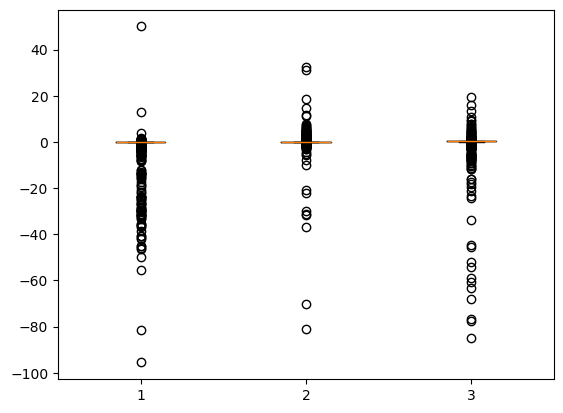

In [57]:
plt.boxplot(A)

In [58]:
sample.keys()

['cross_edge_idx',
 'vert_out_gps',
 'cross_edges',
 'edges_in',
 'sigmas',
 'vert_in_gps',
 'filename',
 'vert_out_features',
 'year',
 'vert_in',
 'edges_out',
 'vert_in_features',
 'edge_idx_in',
 'vert_out',
 'edge_idx_out',
 'input_affinities']

{'whiskers': [<matplotlib.lines.Line2D at 0x37a811cd0>,
 'caps': [<matplotlib.lines.Line2D at 0x37a81e250>,
 'boxes': [<matplotlib.lines.Line2D at 0x37a811a30>],
 'medians': [<matplotlib.lines.Line2D at 0x37a81e670>],
 'fliers': [<matplotlib.lines.Line2D at 0x37a81e910>],
 'means': []}

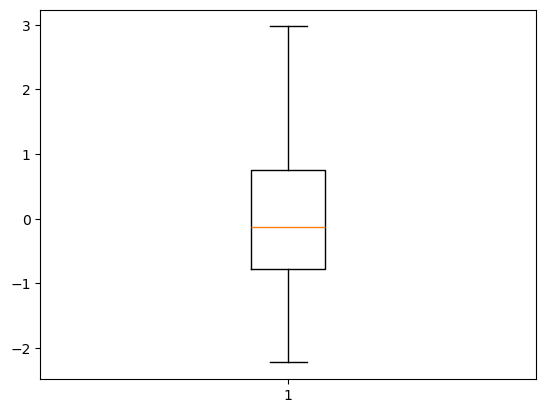

In [62]:
plt.boxplot(sample.vert_in_features[:,0].cpu().numpy())

In [82]:
sample.keys()

['cross_edge_idx',
 'vert_out_gps',
 'cross_edges',
 'edges_in',
 'sigmas',
 'vert_in_gps',
 'filename',
 'vert_out_features',
 'year',
 'vert_in',
 'edges_out',
 'vert_in_features',
 'edge_idx_in',
 'vert_out',
 'edge_idx_out',
 'input_affinities']

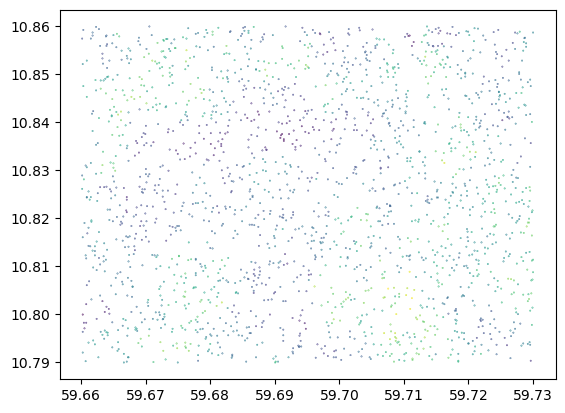

In [83]:
plt.scatter(sample.vert_in_gps.cpu().numpy()[:,0], sample.vert_in_gps.cpu().numpy()[:,1], c = sample.vert_in_features[:,0], s=0.1, cmap='viridis')
#plt.scatter(sample.vert_out_gps.cpu().numpy()[:,0], sample.vert_out_gps.cpu().numpy()[:,1], c = "red", s=0.1)


/var/folders/sw/tjsbk4pj7q9gs_91lbj2_2rc0000gp/T/ipykernel_85658/165391840.py:2: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


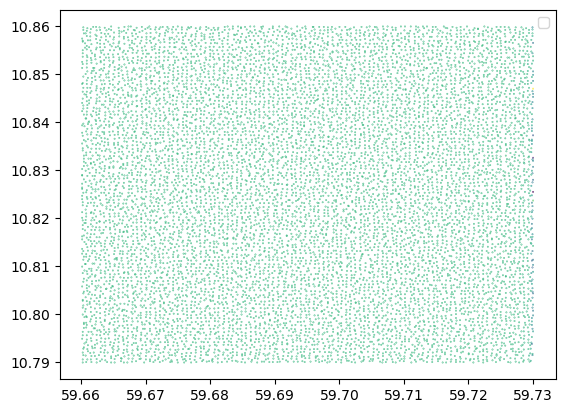

In [ ]:
plt.scatter(sample.vert_out_gps.cpu().numpy()[:,0], sample.vert_out_gps.cpu().numpy()[:,1], c = A[:,0], s=0.1, cmap = 'viridis')


In [9]:
# Choose a year and file (use test year for out-of-sample prediction)
test_year = 2019  # First test year
tif_path = data_path / f'sat_emb_{test_year}.tif'

n_points_input = 25

n_points_output_grid_latitude = 5
n_points_output_grid_longitude = 5

if not tif_path.exists():
    print(f'Warning: File not found: {tif_path}')
    print('Available files:')
    for f in sorted(data_path.glob('sat_emb_*.tif')):
        print(f'  {f.name}')
else:
    print(f'Using data file: {tif_path.name}')
    
    # Define bounding box (use config bounds)
    bbox = (
        config['lon_min'],
        config['lat_min'],
        config['lon_max'],
        config['lat_max']
    )
    
    print(f'Bounding box: lat [{bbox[1]}, {bbox[3]}], lon [{bbox[0]}, {bbox[2]}]')
    
    # Load and prepare data
    print('Loading region data...')
    df = prepare_dataframe(str(tif_path), bbox)
    print(f'Loaded {len(df)} grid points')
    
    # Create output grid from the data
    print('Creating output grid...')
    grid_indices, grid_df_temp = create_regular_grid_from_data(
        df, 
        n_points_output_grid_latitude, 
        n_points_output_grid_longitude
    )
    grid_df = df.iloc[grid_indices].reset_index(drop=True)
    print(f'Created grid with {len(grid_df)} points')
    
    # Create graph sample using same parameters as training
    print('Creating graph sample...')
    sample, _ = create_subgraph_sample(
        df_full=df,
        year=test_year,
        n_points_input_min=n_points_input,
        n_points_input_max=n_points_input,
        grid_df=grid_df,
        k_in=3,
        k_out=3,
        k_cross=3,
        perplexity=3,
        device=device,
        filename=tif_path.name,
        cached_output=None
    )
    
    print(f'Sample created:')
    print(f'  Input nodes: {sample.vert_in.shape[0]}')
    print(f'  Output nodes: {sample.vert_out.shape[0]}')
    print(f'  Input edges: {sample.edge_idx_in.shape[1]}')
    print(f'  Output edges: {sample.edge_idx_out.shape[1]}')
    print(f'  Cross edges: {sample.cross_edge_idx.shape[1]}')
    print(f'  Input features: {sample.vert_in_features.shape[1]}')
    print(f'  Year: {sample.year}')

Using data file: sat_emb_2019.tif
Bounding box: lat [59.66, 59.73], lon [10.79, 10.86]
Loading region data...
Loaded 30000 grid points
Creating output grid...
Created grid with 25 points
Creating graph sample...
Sample created:
  Input nodes: 25
  Output nodes: 25
  Input edges: 75
  Output edges: 75
  Cross edges: 75
  Input features: 64
  Year: 2019


In [10]:
nodes_A = sample.vert_in_gps.cpu()
nodes_B = sample.vert_out_gps.cpu()

edges_A = sample.edge_idx_in.cpu()
edges_B = sample.edge_idx_out.cpu()
edges_AB = sample.cross_edge_idx.cpu()

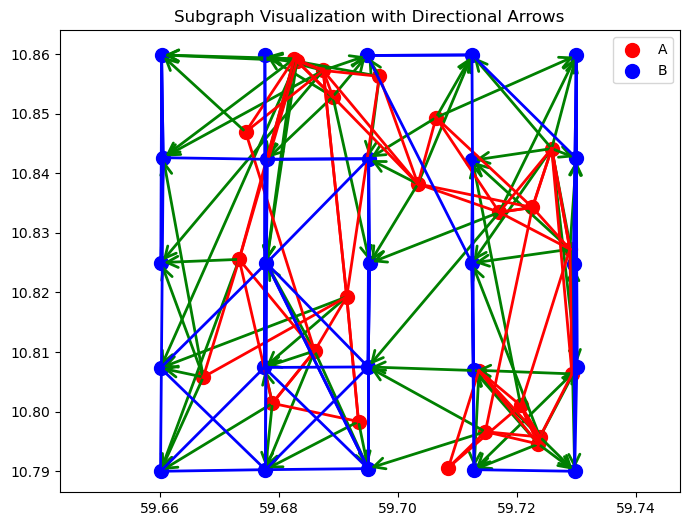

In [11]:
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
# ----------------------
# Plot nodes
# ----------------------
plt.figure(figsize=(8,6))
plt.scatter(nodes_A[:,0].numpy(), nodes_A[:,1].numpy(), color='red', label='A', s=100)
plt.scatter(nodes_B[:,0].numpy(), nodes_B[:,1].numpy(), color='blue', label='B', s=100)

# ----------------------
# Function to plot undirected edges within subgraphs
# ----------------------
def plot_edges(nodes, edges, color):
    for k in range(edges.shape[1]):
        i, j = edges[:, k]
        x = [nodes[int(i), 0].item(), nodes[int(j), 0].item()]
        y = [nodes[int(i), 1].item(), nodes[int(j), 1].item()]
        plt.plot(x, y, color=color, linewidth=2)

# Plot edges within A and B
plot_edges(nodes_A, edges_A, 'red')
plot_edges(nodes_B, edges_B, 'blue')

# ----------------------
# Function to plot directed edges between subgraphs
# ----------------------
def plot_directed_edges(nodes_from, nodes_to, edges, color='green', arrow_size=20):
    for k in range(edges.shape[1]):
        i, j = edges[:, k]  # from index in nodes_from, to index in nodes_to
        start = (nodes_from[int(i), 0].item(), nodes_from[int(i), 1].item())
        end = (nodes_to[int(j), 0].item(), nodes_to[int(j), 1].item())
        arrow = FancyArrowPatch(start, end, arrowstyle='->', color=color,
                                mutation_scale=arrow_size, linewidth=2)
        plt.gca().add_patch(arrow)

# Plot directed edges from A to B
plot_directed_edges(nodes_A, nodes_B, edges_AB, color='green', arrow_size=20)

# ----------------------
# Final plot settings
# ----------------------
plt.legend()
plt.axis('equal')
plt.title("Subgraph Visualization with Directional Arrows")
plt.show()

In [27]:
edges_B[:,42:45]

tensor([[14, 14, 14],
        [ 8,  9, 14]])

In [ ]:
nodes_B[[12,13,16,17],:]

tensor([[59.6950, 10.7904],
        [59.6950, 10.8075],
        [59.6779, 10.8249],
        [59.6777, 10.7902]])

In [24]:
nodes_B[14,:]

tensor([59.6948, 10.8598])